In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')

# Postavke za vizualizaciju
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 12
sns.set_palette('Set2')

# Prikaz svih kolona u DataFrame-u
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)
pd.set_option('display.float_format', lambda x: '%.4f' % x)

print('===========Biblioteke uspješno učitane===========')

===========Biblioteke uspješno učitane===========


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

DATASET_PATH = '/content/drive/MyDrive/MPVI/Dataset/'

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# Učitavanje training i testing seta
TRAIN_PATH = DATASET_PATH + 'Training and Testing Sets/UNSW_NB15_training-set.csv'
TEST_PATH  = DATASET_PATH + 'Training and Testing Sets/UNSW_NB15_testing-set.csv'

df_train = pd.read_csv(TRAIN_PATH)
df_test  = pd.read_csv(TEST_PATH)

print(f'Training set: {df_train.shape[0]:,} zapisa, {df_train.shape[1]} kolona')
print(f'Testing set:  {df_test.shape[0]:,} zapisa, {df_test.shape[1]} kolona')
print(f'Ukupno:       {df_train.shape[0] + df_test.shape[0]:,} zapisa')

Training set: 175,341 zapisa, 45 kolona
Testing set:  82,332 zapisa, 45 kolona
Ukupno:       257,673 zapisa


In [ ]:
# Kombinovanje za potpunu analizu
df_train['source'] = 'train'
df_test['source']  = 'test'
df = pd.concat([df_train, df_test], axis=0, ignore_index=True)

print(f'Kombinovani dataset: {df.shape[0]:,} zapisa, {df.shape[1]} kolona')

Kombinovani dataset: 257,673 zapisa, 46 kolona


In [ ]:
# Učitavanje opisa feature-a
features_df = pd.read_csv(DATASET_PATH + 'NUSW-NB15_features.csv', encoding='latin1')
print('Feature-i dataseta:')
display(features_df)

Feature-i dataseta:


,No.,Name,Type,Description
0,1,srcip,nominal,Source IP address
1,2,sport,integer,Source port number
2,3,dstip,nominal,Destination IP address
3,4,dsport,integer,Destination port number
4,5,proto,nominal,Transaction protocol
5,6,state,nominal,Indicates to the state and its dependent proto...
6,7,dur,Float,Record total duration
7,8,sbytes,Integer,Source to destination transaction bytes
8,9,dbytes,Integer,Destination to source transaction bytes
9,10,sttl,Integer,Source to destination time to live value


In [ ]:
#UCITAVANJE SIROVOG DATASETA SA 2.5M zapisa bez headera

column_names = [
    'srcip', 'sport', 'dstip', 'dsport', 'proto', 'state', 'dur',
    'sbytes', 'dbytes', 'sttl', 'dttl', 'sloss', 'dloss', 'service',
    'Sload', 'Dload', 'Spkts', 'Dpkts', 'swin', 'dwin', 'stcpb',
    'dtcpb', 'smeansz', 'dmeansz', 'trans_depth', 'res_bdy_len',
    'Sjit', 'Djit', 'Stime', 'Ltime', 'Sintpkt', 'Dintpkt',
    'tcprtt', 'synack', 'ackdat', 'is_sm_ips_ports', 'ct_state_ttl',
    'ct_flw_http_mthd', 'is_ftp_login', 'ct_ftp_cmd', 'ct_srv_src',
    'ct_srv_dst', 'ct_dst_ltm', 'ct_src_ltm', 'ct_src_dport_ltm',
    'ct_dst_sport_ltm', 'ct_dst_src_ltm', 'attack_cat', 'label'
]
raw_files = [f'{DATASET_PATH}UNSW-NB15_{i}.csv' for i in range(1, 5)]
df_raw = pd.concat(
    [pd.read_csv(f, header=None, names=column_names, low_memory=False) for f in raw_files],
    ignore_index=True
)
print(f'Sirovi dataset: {df_raw.shape[0]:,} zapisa, {df_raw.shape[1]} kolona')

Sirovi dataset: 2,540,047 zapisa, 49 kolona


In [ ]:
# Prvih 5 redova
print('=== Prvih 5 redova ===')
display(df.head())

=== Prvih 5 redova ===


,id,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,sttl,dttl,sload,dload,sloss,dloss,sinpkt,dinpkt,sjit,djit,swin,stcpb,dtcpb,dwin,tcprtt,synack,ackdat,smean,dmean,trans_depth,response_body_len,ct_srv_src,ct_state_ttl,ct_dst_ltm,ct_src_dport_ltm,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,attack_cat,label,source
0,1,0.1215,tcp,-,FIN,6,4,258,172,74.0875,252,254,14158.9424,8495.3652,0,0,24.2956,8.3750,30.1775,11.8306,255,621772692,2202533631,255,0.0000,0.0000,0.0000,43,43,0,0,1,0,1,1,1,1,0,0,0,1,1,0,Normal,0,train
1,2,0.6499,tcp,-,FIN,14,38,734,42014,78.4734,62,252,8395.1123,503571.3125,2,17,49.9150,15.4329,61.4269,1387.7783,255,1417884146,3077387971,255,0.0000,0.0000,0.0000,52,1106,0,0,43,1,1,1,1,2,0,0,0,1,6,0,Normal,0,train
2,3,1.6231,tcp,-,FIN,8,16,364,13186,14.1702,62,252,1572.2719,60929.2305,1,6,231.8756,102.7372,17179.5869,11420.9262,255,2116150707,2963114973,255,0.1119,0.0615,0.0504,46,824,0,0,7,1,2,1,1,3,0,0,0,2,6,0,Normal,0,train
3,4,1.6816,tcp,ftp,FIN,12,12,628,770,13.6771,62,252,2740.1790,3358.6221,1,3,152.8765,90.2357,259.0802,4991.7847,255,1107119177,1047442890,255,0.0000,0.0000,0.0000,52,64,0,0,1,1,2,1,1,3,1,1,0,2,1,0,Normal,0,train
4,5,0.4495,tcp,-,FIN,10,6,534,268,33.3738,254,252,8561.4990,3987.0598,2,1,47.7503,75.6596,2415.8376,115.8070,255,2436137549,1977154190,255,0.1284,0.0711,0.0572,53,45,0,0,43,1,2,2,1,40,0,0,0,2,39,0,Normal,0,train


In [ ]:
# Posljednjih 5 redova
print('=== Posljednjih 5 redova ===')
display(df.tail())

=== Posljednjih 5 redova ===


,id,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,sttl,dttl,sload,dload,sloss,dloss,sinpkt,dinpkt,sjit,djit,swin,stcpb,dtcpb,dwin,tcprtt,synack,ackdat,smean,dmean,trans_depth,response_body_len,ct_srv_src,ct_state_ttl,ct_dst_ltm,ct_src_dport_ltm,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,attack_cat,label,source
257668,82328,0.0000,udp,-,INT,2,0,104,0,200000.0051,254,0,83200000.0000,0.0000,0,0,0.0050,0.0000,0.0000,0.0000,0,0,0,0,0.0000,0.0000,0.0000,52,0,0,0,1,2,2,1,1,2,0,0,0,2,1,0,Normal,0,test
257669,82329,1.1061,tcp,-,FIN,20,8,18062,354,24.4101,254,252,124104.3984,2242.1099,7,1,55.8801,143.7000,4798.1310,190.9808,255,1072535109,3284291478,255,0.1732,0.1002,0.0730,903,44,0,0,1,1,2,1,1,1,0,0,0,3,2,0,Normal,0,test
257670,82330,0.0000,arp,-,INT,1,0,46,0,0.0000,0,0,0.0000,0.0000,0,0,60000.7200,0.0000,0.0000,0.0000,0,0,0,0,0.0000,0.0000,0.0000,46,0,0,0,1,2,1,1,1,1,0,0,0,1,1,1,Normal,0,test
257671,82331,0.0000,arp,-,INT,1,0,46,0,0.0000,0,0,0.0000,0.0000,0,0,60000.7320,0.0000,10.9545,0.0000,0,0,0,0,0.0000,0.0000,0.0000,46,0,0,0,1,2,1,1,1,1,0,0,0,1,1,1,Normal,0,test
257672,82332,0.0000,udp,-,INT,2,0,104,0,111111.1072,254,0,46222220.0000,0.0000,0,0,0.0090,0.0000,0.0000,0.0000,0,0,0,0,0.0000,0.0000,0.0000,52,0,0,0,1,2,1,1,1,1,0,0,0,1,1,0,Normal,0,test


In [ ]:
# Informacije o datasetu
print('=== Informacije o datasetu ===')
df.info()

=== Informacije o datasetu ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 257673 entries, 0 to 257672
Data columns (total 46 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   id                 257673 non-null  int64  
 1   dur                257673 non-null  float64
 2   proto              257673 non-null  object 
 3   service            257673 non-null  object 
 4   state              257673 non-null  object 
 5   spkts              257673 non-null  int64  
 6   dpkts              257673 non-null  int64  
 7   sbytes             257673 non-null  int64  
 8   dbytes             257673 non-null  int64  
 9   rate               257673 non-null  float64
 10  sttl               257673 non-null  int64  
 11  dttl               257673 non-null  int64  
 12  sload              257673 non-null  float64
 13  dload              257673 non-null  float64
 14  sloss              257673 non-null  int64  
 15  dloss              2

In [ ]:
# Tipovi podataka
print('=== Tipovi podataka ===')
print(df.dtypes)
print(f'\nBroj numeričkih kolona: {df.select_dtypes(include=[np.number]).shape[1]}')
print(f'Broj kategoričkih kolona: {df.select_dtypes(include=["object"]).shape[1]}')

=== Tipovi podataka ===
id                     int64
dur                  float64
proto                 object
service               object
state                 object
spkts                  int64
dpkts                  int64
sbytes                 int64
dbytes                 int64
rate                 float64
sttl                   int64
dttl                   int64
sload                float64
dload                float64
sloss                  int64
dloss                  int64
sinpkt               float64
dinpkt               float64
sjit                 float64
djit                 float64
swin                   int64
stcpb                  int64
dtcpb                  int64
dwin                   int64
tcprtt               float64
synack               float64
ackdat               float64
smean                  int64
dmean                  int64
trans_depth            int64
response_body_len      int64
ct_srv_src             int64
ct_state_ttl           int64
ct_dst_ltm         

In [ ]:
# Deskriptivna statistika numeričkih kolona
print('=== Deskriptivna statistika (numeričke kolone) ===')
display(df.describe().T)

=== Deskriptivna statistika (numeričke kolone) ===


,count,mean,std,min,25%,50%,75%,max
id,257673.0000,72811.8239,48929.9176,1.0000,32210.0000,64419.0000,110923.0000,175341.0000
dur,257673.0000,1.2467,5.9743,0.0000,0.0000,0.0043,0.6858,60.0000
spkts,257673.0000,19.7771,135.9472,1.0000,2.0000,4.0000,12.0000,10646.0000
dpkts,257673.0000,18.5147,111.9860,0.0000,0.0000,2.0000,10.0000,11018.0000
sbytes,257673.0000,8572.9518,173773.8806,24.0000,114.0000,528.0000,1362.0000,14355774.0000
dbytes,257673.0000,14387.2875,146199.2819,0.0000,0.0000,178.0000,1064.0000,14657531.0000
rate,257673.0000,91253.9124,160344.6367,0.0000,30.7893,2955.6649,125000.0003,1000000.0030
sttl,257673.0000,180.0009,102.4883,0.0000,62.0000,254.0000,254.0000,255.0000
dttl,257673.0000,84.7550,112.7621,0.0000,0.0000,29.0000,252.0000,254.0000
sload,257673.0000,70608691.2282,185731252.8418,0.0000,12318.0049,743942.3125,80000000.0000,5988000256.0000


In [ ]:
# Deskriptivna statistika kategoričkih kolona
print('=== Deskriptivna statistika (kategoričke kolone) ===')
display(df.describe(include='object').T)

=== Deskriptivna statistika (kategoričke kolone) ===


,count,unique,top,freq
proto,257673,133,tcp,123041
service,257673,13,-,141321
state,257673,11,FIN,117164
attack_cat,257673,10,Normal,93000
source,257673,2,train,175341


In [ ]:
# Oblik dataseta
print(f'Oblik dataseta: {df.shape}')
print(f'Ukupan broj ćelija: {df.shape[0] * df.shape[1]:,}')
print(f'Memorija: {df.memory_usage(deep=True).sum() / 1024**2:.2f} MB')

Oblik dataseta: (257673, 46)
Ukupan broj ćelija: 11,852,958
Memorija: 145.72 MB


In [ ]:
# Provjera nedostajućih vrijednosti
missing = df.isnull().sum()
missing_pct = (df.isnull().sum() / len(df)) * 100

missing_df = pd.DataFrame({
    'Nedostajuće': missing,
    'Procenat (%)': missing_pct
}).sort_values('Nedostajuće', ascending=False)

# Prikaz samo kolona koje imaju nedostajuće vrijednosti
missing_with_values = missing_df[missing_df['Nedostajuće'] > 0]

if len(missing_with_values) > 0:
    print(f'Kolone sa nedostajućim vrijednostima: {len(missing_with_values)}')
    display(missing_with_values)
else:
    print('✅ Nema nedostajućih vrijednosti (NaN) u datasetu.')

print(f'\nUkupno nedostajućih: {missing.sum():,} od {df.shape[0] * df.shape[1]:,} ćelija')

✅ Nema nedostajućih vrijednosti (NaN) u datasetu.

Ukupno nedostajućih: 0 od 11,852,958 ćelija


In [ ]:
# Provjera praznih stringova i specijalnih vrijednosti
print('=== Provjera specijalnih vrijednosti ===')
for col in df.select_dtypes(include='object').columns:
    unique_vals = df[col].unique()
    has_dash = '-' in unique_vals
    has_empty = '' in unique_vals
    has_space = ' ' in unique_vals
    if has_dash or has_empty or has_space:
        print(f'  {col}: {"-" if has_dash else ""} {"prazan string" if has_empty else ""} {"razmak" if has_space else ""}')
        if has_dash:
            print(f'    Broj \'-\' vrijednosti: {(df[col] == "-").sum()}')

=== Provjera specijalnih vrijednosti ===
  service: -  
    Broj '-' vrijednosti: 141321


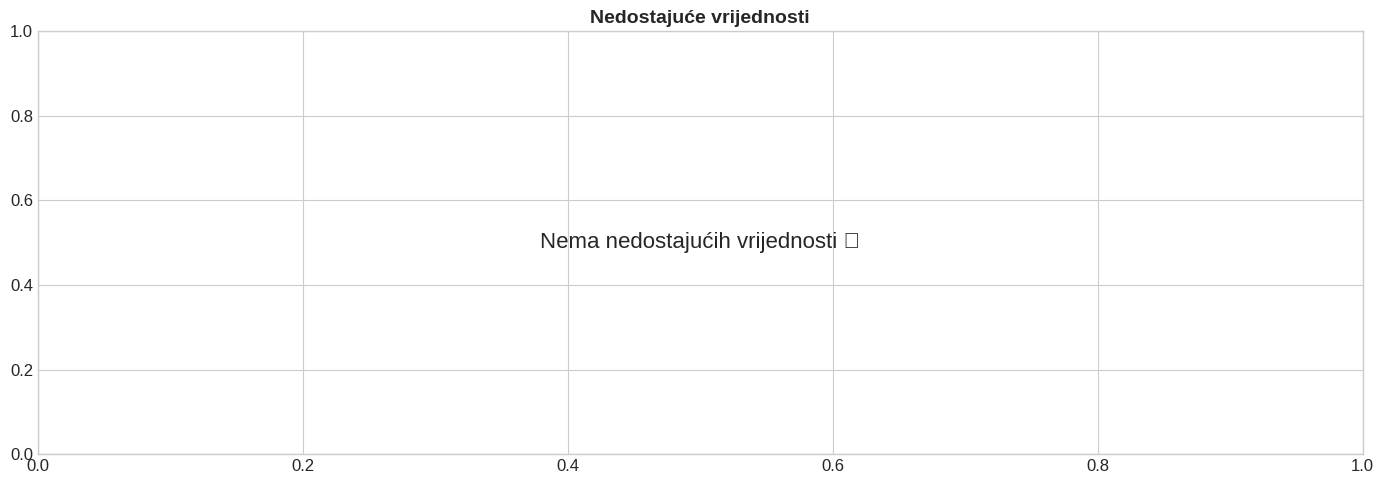

In [ ]:
# Vizualizacija nedostajućih vrijednosti
fig, ax = plt.subplots(figsize=(14, 5))

null_counts = df.isnull().sum()
if null_counts.sum() > 0:
    null_counts[null_counts > 0].plot(kind='bar', ax=ax, color='coral')
    ax.set_title('Nedostajuće vrijednosti po kolonama', fontsize=14, fontweight='bold')
    ax.set_ylabel('Broj nedostajućih')
    ax.tick_params(axis='x', rotation=45)
else:
    ax.text(0.5, 0.5, 'Nema nedostajućih vrijednosti ✅',
            ha='center', va='center', fontsize=16, transform=ax.transAxes)
    ax.set_title('Nedostajuće vrijednosti', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()

In [ ]:
# Distribucija label-a (0 = Normal, 1 = Attack)
print('=== Distribucija ciljne varijable (label) ===')
label_counts = df['label'].value_counts()
label_pct = df['label'].value_counts(normalize=True) * 100

label_summary = pd.DataFrame({
    'Broj zapisa': label_counts,
    'Procenat (%)': label_pct
})
label_summary.index = ['Normal (0)' if i == 0 else 'Napad (1)' for i in label_summary.index]
display(label_summary)

print(f'\nOdnos Normal:Napad = 1:{label_counts[1]/label_counts[0]:.2f}')

=== Distribucija ciljne varijable (label) ===


,Broj zapisa,Procenat (%)
Napad (1),164673,63.9077
Normal (0),93000,36.0923



Odnos Normal:Napad = 1:1.77


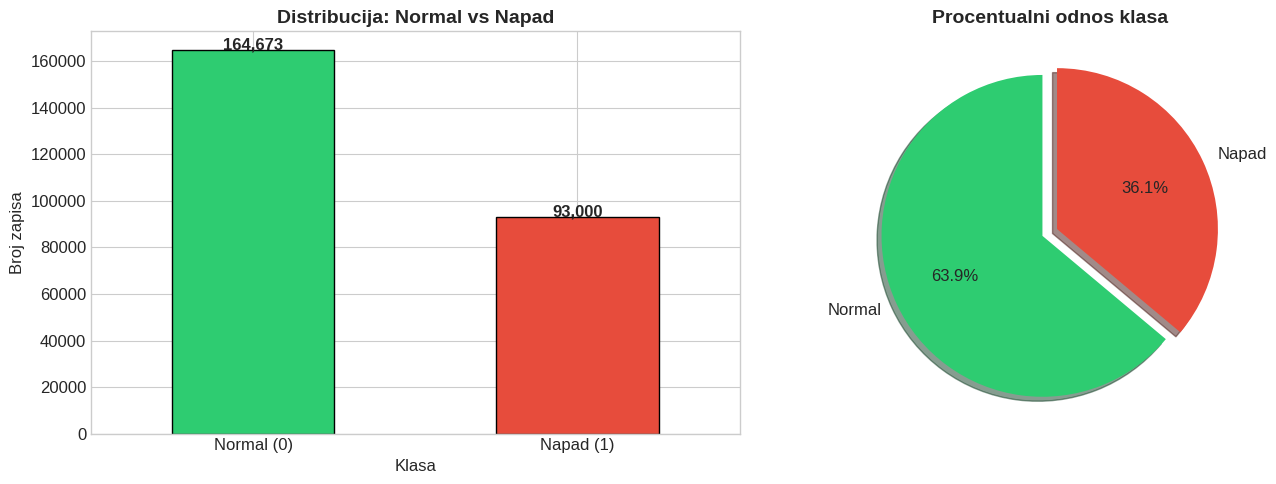

In [ ]:
# Vizualizacija distribucije label-a
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Bar chart
colors = ['#2ecc71', '#e74c3c']
label_counts.plot(kind='bar', ax=axes[0], color=colors, edgecolor='black')
axes[0].set_title('Distribucija: Normal vs Napad', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Klasa')
axes[0].set_ylabel('Broj zapisa')
axes[0].set_xticklabels(['Normal (0)', 'Napad (1)'], rotation=0)
for i, v in enumerate(label_counts):
    axes[0].text(i, v + 500, f'{v:,}', ha='center', fontweight='bold')

# Pie chart
axes[1].pie(label_counts, labels=['Normal', 'Napad'], autopct='%1.1f%%',
            colors=colors, startangle=90, explode=(0.05, 0.05),
            shadow=True, textprops={'fontsize': 12})
axes[1].set_title('Procentualni odnos klasa', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()

=== Distribucija po Train/Test setovima ===


,Normal (0),Napad (1),Ukupno
source,,,
test,37000,45332,82332
train,56000,119341,175341
Ukupno,93000,164673,257673


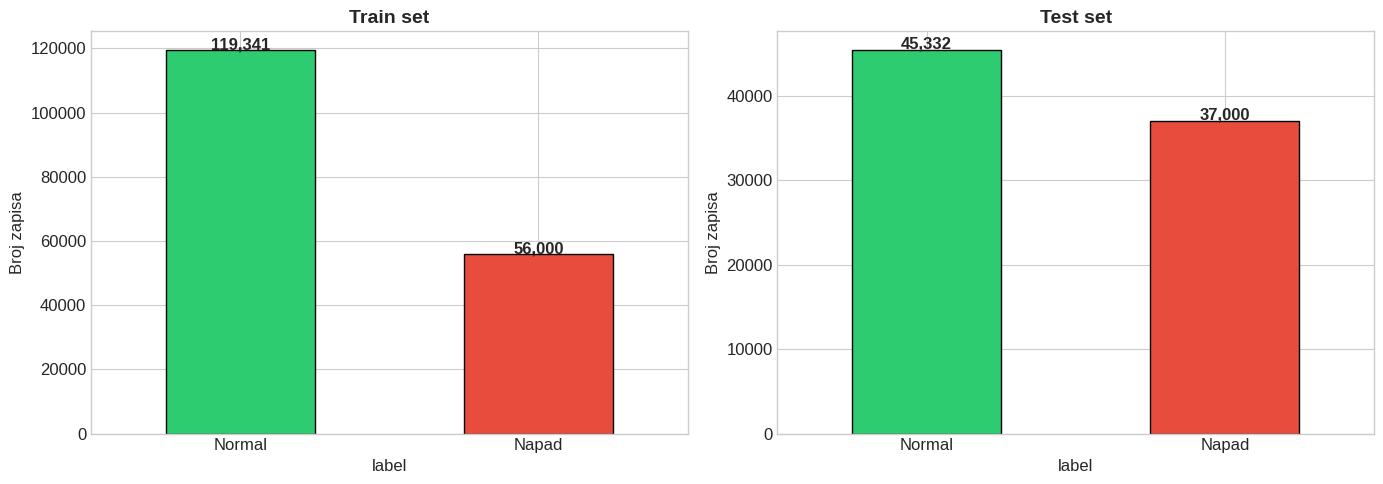

In [ ]:
# Distribucija label-a po Train/Test setu
print('=== Distribucija po Train/Test setovima ===')
cross_tab = pd.crosstab(df['source'], df['label'], margins=True, margins_name='Ukupno')
cross_tab.columns = ['Normal (0)', 'Napad (1)', 'Ukupno']
display(cross_tab)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for idx, src in enumerate(['train', 'test']):
    subset = df[df['source'] == src]['label'].value_counts()
    subset.plot(kind='bar', ax=axes[idx], color=colors, edgecolor='black')
    axes[idx].set_title(f'{src.capitalize()} set', fontsize=14, fontweight='bold')
    axes[idx].set_xticklabels(['Normal', 'Napad'], rotation=0)
    axes[idx].set_ylabel('Broj zapisa')
    for i, v in enumerate(subset):
        axes[idx].text(i, v + 200, f'{v:,}', ha='center', fontweight='bold')

plt.tight_layout()
plt.show()